In [4]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [5]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

C:\Users\DELL\AppData\Roaming\Python\Python312\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = RestrictedUnpickler(f, encoding="bytes").load()


In [6]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nX_train dtype:", X_train.dtype)
print("y_train dtype:", y_train.dtype)

print("\nUnique y values:", np.unique(y_train))

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)

X_train dtype: uint8
y_train dtype: uint8

Unique y values: [0 1 2 3 4 5 6 7 8 9]


In [7]:
class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

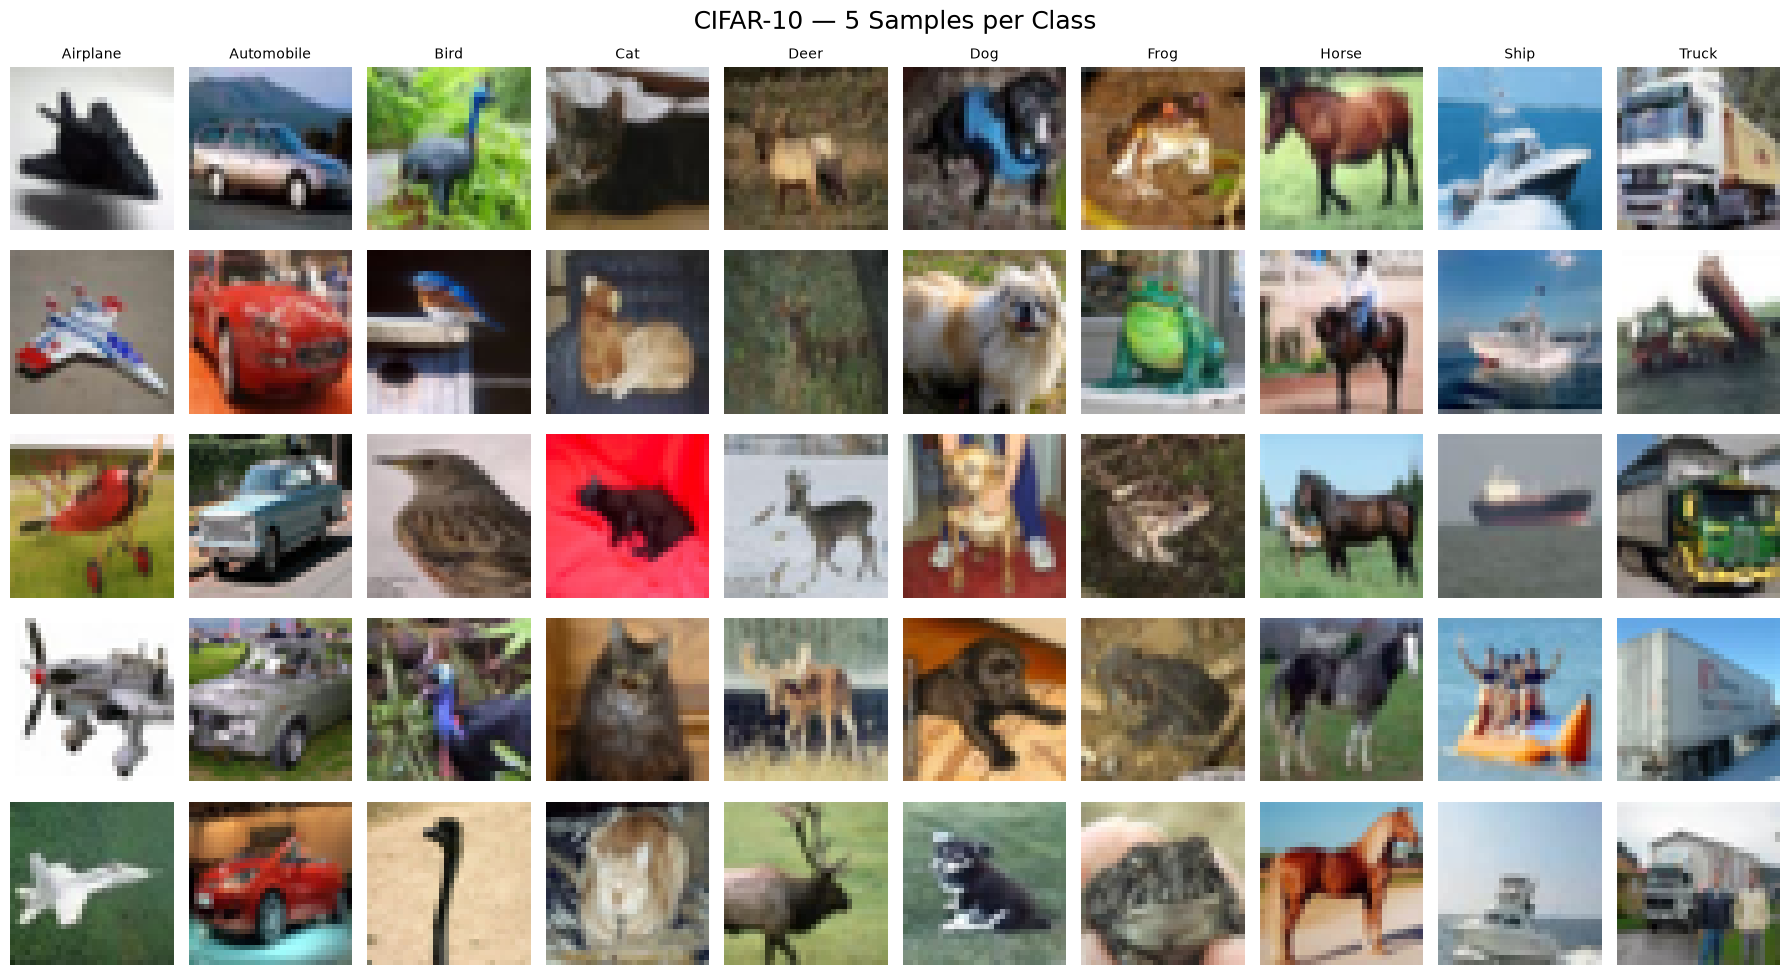

In [8]:
plt.figure(figsize=(18, 10))

for class_id in range(10):
    
    # Find images belonging to this class
    class_indices = np.where(y_train.flatten() == class_id)[0][:5]
    
    for row, image_index in enumerate(class_indices):
        
        # Position in the 5 x 10 grid
        position = row * 10 + class_id + 1
        
        plt.subplot(5, 10, position)
        plt.imshow(X_train[image_index])
        plt.axis("off")
        
        # Put class name on the first row
        if row == 0:
            plt.title(class_names[class_id], fontsize=10)

plt.suptitle(
    "CIFAR-10 — 5 Samples per Class",
    fontsize=18
)

plt.tight_layout()
plt.show()

## Visual Observation

CIFAR-10 contains several classes that are visually similar. The hardest pairs are expected to be:

- **Cat vs Dog:** Both are animals with similar shapes, colours, and body structures. The small 32×32 image resolution makes fine-grained differences difficult to identify.
- **Automobile vs Truck:** Both are road vehicles with similar shapes, colours, and backgrounds. The CNN must learn subtle visual features such as body shape and proportions.

These visually similar classes are expected to have higher confusion during classification.

# Pixel Distribution Before Normalisation

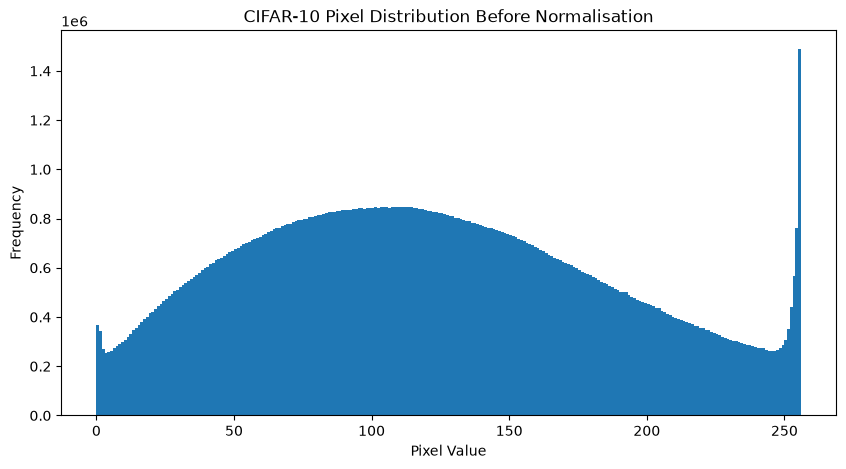

In [9]:
plt.figure(figsize=(10, 5))

plt.hist(
    X_train.flatten(),
    bins=256,
    range=(0, 256)
)

plt.title("CIFAR-10 Pixel Distribution Before Normalisation")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.show()

#   Normalize

In [10]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [11]:
print("X_train dtype:", X_train.dtype)
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

X_train dtype: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


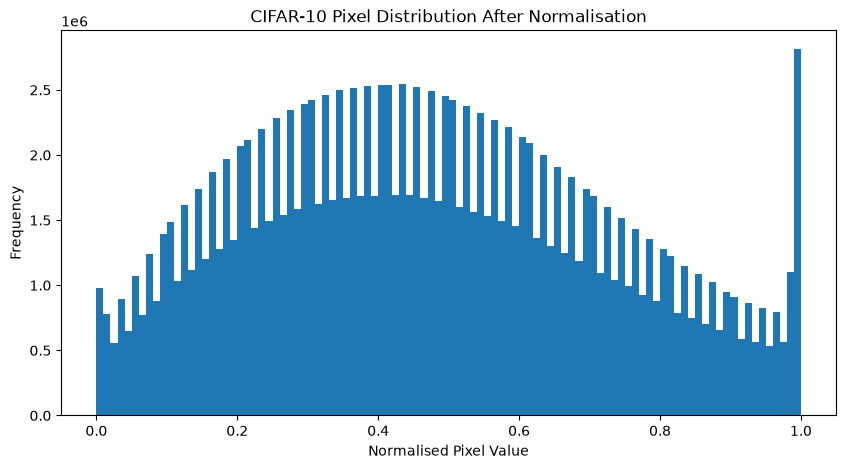

In [12]:
plt.figure(figsize=(10, 5))

plt.hist(
    X_train.flatten(),
    bins=100,
    range=(0, 1)
)

plt.title("CIFAR-10 Pixel Distribution After Normalisation")
plt.xlabel("Normalised Pixel Value")
plt.ylabel("Frequency")

plt.show()

## Why Normalise Pixel Values?

The original CIFAR-10 pixel values range from 0 to 255. We divide the values by 255 so that all pixel values lie in the range [0, 1].

Normalisation helps gradient descent converge more efficiently because the input values are on a smaller and consistent scale. Large raw pixel values can result in proportionally larger weight updates during early training, which can make optimisation less stable.

Therefore, the CNN receives normalised floating-point inputs instead of raw uint8 pixel values.

In [13]:
y_train_ohe = keras.utils.to_categorical(y_train, 10)
y_test_ohe = keras.utils.to_categorical(y_test, 10)

In [14]:
print("Original y_train shape:", y_train.shape)
print("One-hot y_train shape:", y_train_ohe.shape)

print("Original y_test shape:", y_test.shape)
print("One-hot y_test shape:", y_test_ohe.shape)

Original y_train shape: (50000, 1)
One-hot y_train shape: (50000, 10)
Original y_test shape: (10000, 1)
One-hot y_test shape: (10000, 10)


In [15]:
print("Original label:", y_train[0])
print("One-hot label:", y_train_ohe[0])

Original label: [6]
One-hot label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


## Why One-Hot Encode the Labels?

The CNN will use a softmax output layer containing 10 neurons, one for each CIFAR-10 class. Softmax produces a probability distribution across the 10 classes.

One-hot encoding represents the correct class as a vector of 10 values, where the correct class has value 1 and all other classes have value 0.

For example, class 6 (Frog) is represented as:

[0, 0, 0, 0, 0, 0, 1, 0, 0, 0]

This representation works naturally with `categorical_crossentropy`, which compares the predicted probability distribution with the one-hot encoded ground-truth label.

If integer class labels were used instead, the appropriate loss function would be `sparse_categorical_crossentropy`.

# CNN vs ANN for Image Classification

## ANN / MLP

A traditional Artificial Neural Network (ANN), also called a Multi-Layer Perceptron (MLP), usually flattens an image into a one-dimensional vector before feeding it into dense layers.

For a CIFAR-10 image:

32 × 32 × 3 = 3,072 input values

After flattening, the spatial arrangement of the pixels is no longer explicitly represented. The network therefore does not naturally understand that neighbouring pixels belong to the same local image structure.

## CNN

A Convolutional Neural Network (CNN) processes the image while preserving its spatial structure.

A small learnable filter, or kernel, slides across the image and detects local patterns such as edges, textures, and shapes.

The same filter weights are reused at different spatial locations. Therefore, if the same pattern appears in another part of the image, the filter can detect it there as well. This provides translation-aware feature detection.

## Parameter Sharing

CNNs also require far fewer parameters than an equivalent fully connected network because the same filter weights are shared across spatial positions.

For example, a 3×3 convolution filter contains only:

3 × 3 = 9 weights

for a single-channel image.

The same 9 weights are reused across different positions of the image rather than learning separate weights for every position.

In contrast, a fully connected layer connecting all 1,024 pixels of a 32×32 grayscale image to one neuron would require 1,024 independent weights.

Therefore, CNNs are computationally more efficient for image feature extraction and are better suited to learning spatial patterns.

In [16]:
from scipy.signal import convolve2d

In [17]:
image = X_train[0]

print("Image shape:", image.shape)

Image shape: (32, 32, 3)


In [18]:
gray = np.mean(image, axis=2)

print("Grayscale shape:", gray.shape)

Grayscale shape: (32, 32)


In [19]:
kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

print(kernel)

[[-1 -1 -1]
 [-1  8 -1]
 [-1 -1 -1]]


In [20]:
convolved = convolve2d(
    gray,
    kernel,
    mode="valid"
)

print("Original shape:", gray.shape)
print("Convolved shape:", convolved.shape)

Original shape: (32, 32)
Convolved shape: (30, 30)


Display Original + Convolved Image

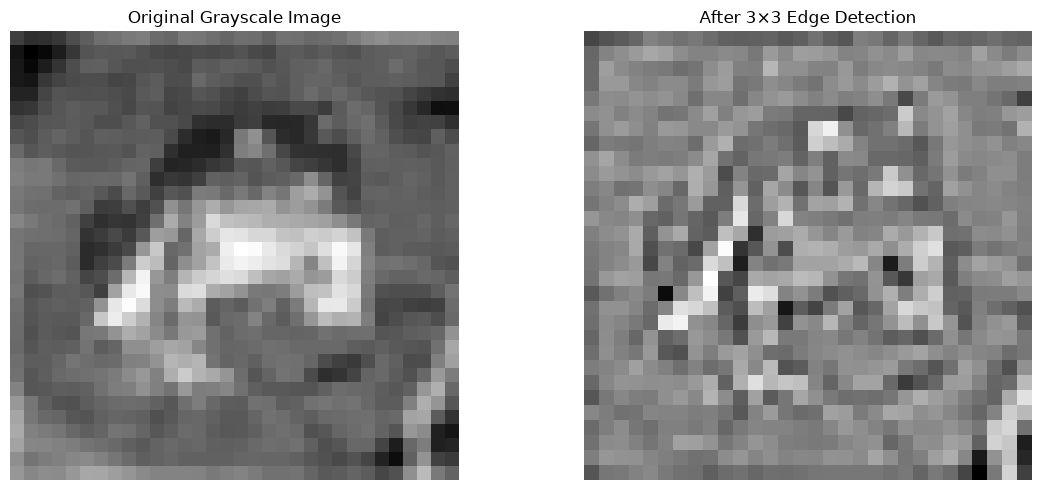

In [21]:
plt.figure(figsize=(12, 5))

# Original grayscale image
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

# Convolved feature map
plt.subplot(1, 2, 2)
plt.imshow(convolved, cmap="gray")
plt.title("After 3×3 Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

## How Convolution Works

The convolution operation computes a dot product between the kernel and each overlapping patch of the image.

The kernel slides across the image one step at a time according to the stride. At each position, the corresponding pixel values and kernel values are multiplied and summed to produce one value in the output feature map.

For example, a 3×3 kernel operates on a 3×3 region of the image at a time.

The kernel then moves across the image and repeats the operation, producing a feature map.

This is the basic operation performed by CNN `Conv2D` layers. In a real CNN, the kernel weights are learnable and multiple filters are used to learn different visual features.

Padding: VALID vs SAME

In [22]:
model_valid = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(
        8,
        (3, 3),
        strides=1,
        padding="valid"
    )
])

print("VALID output shape:", model_valid.output_shape)

VALID output shape: (None, 30, 30, 8)


In [23]:
model_same = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(
        8,
        (3, 3),
        strides=1,
        padding="same"
    )
])

print("SAME output shape:", model_same.output_shape)

SAME output shape: (None, 32, 32, 8)


In [24]:
padded_image = np.pad(
    gray,
    pad_width=1,
    mode="constant",
    constant_values=0
)

print("Original shape:", gray.shape)
print("Padded shape:", padded_image.shape)

Original shape: (32, 32)
Padded shape: (34, 34)


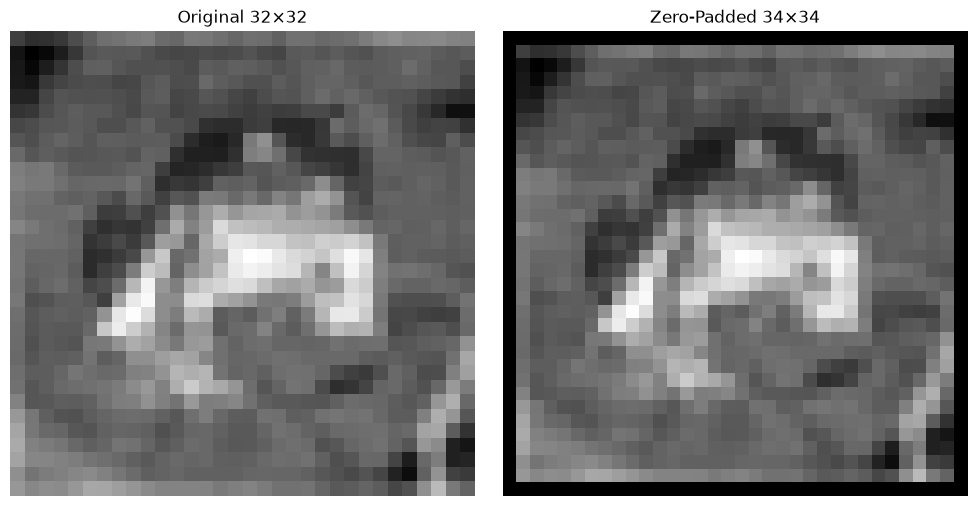

In [25]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original 32×32")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(padded_image, cmap="gray")
plt.title("Zero-Padded 34×34")
plt.axis("off")

plt.tight_layout()
plt.show()

## VALID vs SAME Padding

### VALID Padding

`VALID` padding applies the convolution without adding pixels around the image border.

For a 32×32 input with a 3×3 kernel and stride 1:

Output size = (32 − 3) / 1 + 1 = 30

Therefore, the output feature map has spatial dimensions 30×30.

### SAME Padding

`SAME` padding adds zero-padding around the border so that the output spatial dimensions are preserved when stride = 1.

For a 32×32 input with a 3×3 kernel and stride 1:

Output size = 32×32

SAME padding is commonly used in CNN architectures because it allows multiple convolutional layers to be stacked without shrinking the spatial dimensions too quickly.

Strides Effect

In [26]:
model_stride1 = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(
        8,
        (3, 3),
        strides=1,
        padding="same"
    )
])

print("Stride 1 output:", model_stride1.output_shape)

Stride 1 output: (None, 32, 32, 8)


In [27]:
model_stride2 = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(
        8,
        (3, 3),
        strides=2,
        padding="same"
    )
])

print("Stride 2 output:", model_stride2.output_shape)

Stride 2 output: (None, 16, 16, 8)


## Effect of Stride

Stride determines how many pixels the convolution filter moves at each step.

- **Stride = 1:** The filter moves one pixel at a time, producing a dense feature map.
- **Stride = 2:** The filter moves two pixels at a time, reducing the spatial dimensions.

With SAME padding and a 32×32 input, stride 2 produces a 16×16 output.

Strided convolution can therefore perform downsampling. Unlike fixed pooling operations, the convolution filters are learned from the training data.

Modern object-detection architectures such as YOLO use strided convolutions as part of their feature-extraction and downsampling process.

In [28]:
model_vis = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    )
])

In [29]:
sample_image = X_train[0:1]

print("Input shape:", sample_image.shape)

Input shape: (1, 32, 32, 3)


In [30]:
feature_maps = model_vis.predict(sample_image, verbose=0)

print("Feature map shape:", feature_maps.shape)

Feature map shape: (1, 32, 32, 16)


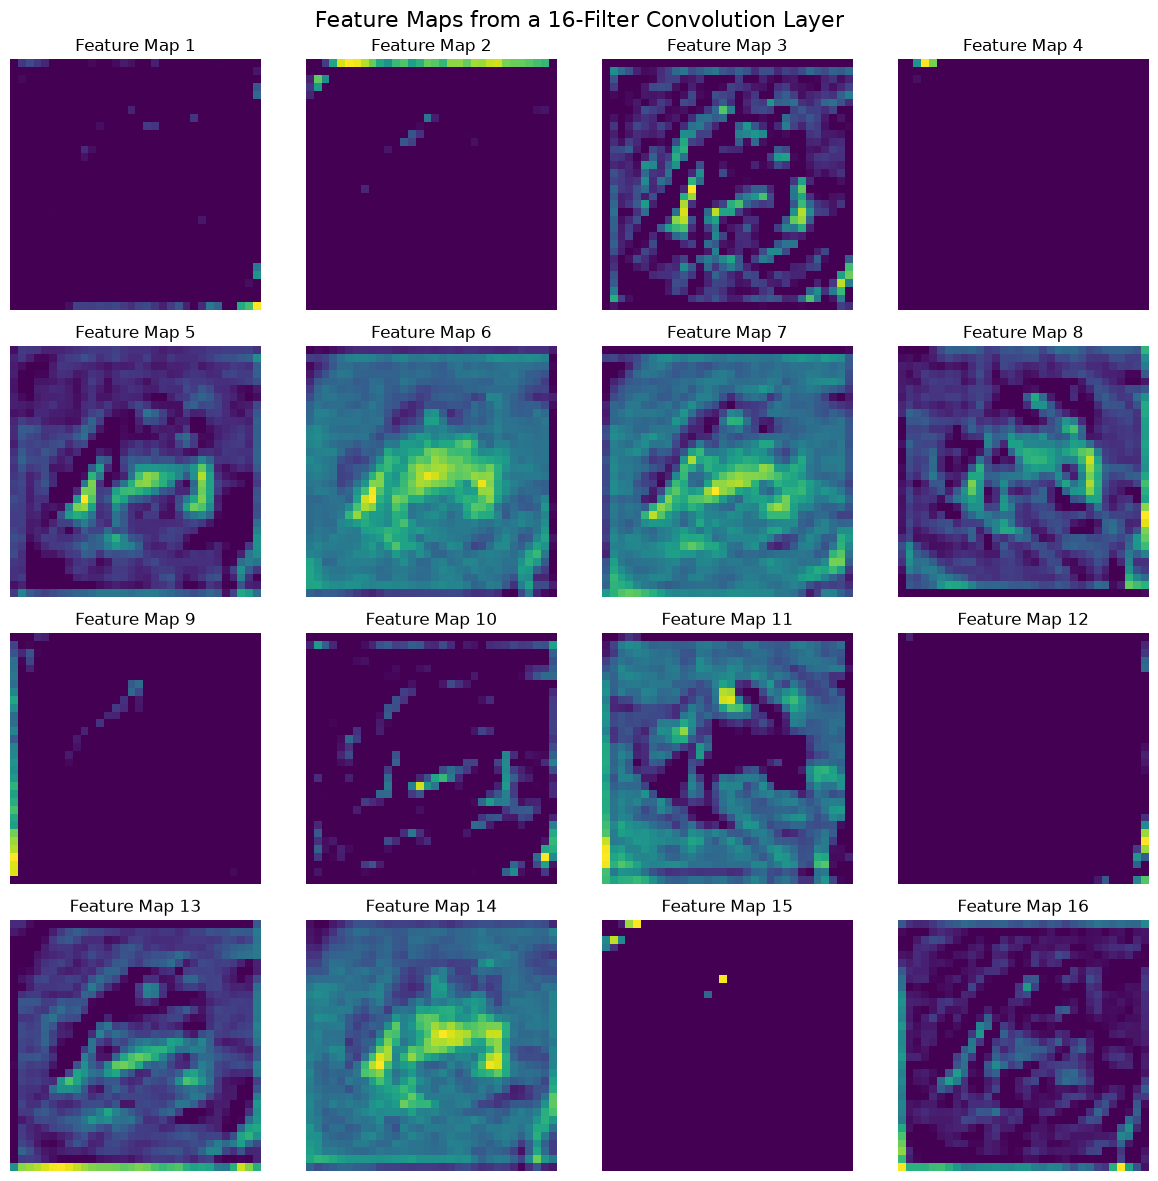

In [31]:
plt.figure(figsize=(12, 12))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    
    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")
    plt.title(f"Feature Map {i + 1}")
    plt.axis("off")

plt.suptitle(
    "Feature Maps from a 16-Filter Convolution Layer",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Understanding CNN Feature Maps

Each feature map is produced by one learnable convolution filter.

The Conv2D layer contains 16 filters, so the output contains 16 feature maps. Each filter learns to respond strongly to particular visual patterns.

In the early layers of a trained CNN, filters commonly learn low-level features such as edges, gradients, colours, and simple textures. As the network becomes deeper, these low-level features are combined into more complex patterns such as shapes and object parts.

The output of this visualization layer has the shape:

1 × 32 × 32 × 16

where:

- 1 = number of input images
- 32 × 32 = spatial dimensions
- 16 = number of learned filters / feature maps

The filters in an untrained model are randomly initialized. Meaningful feature detection develops as the filters are updated through backpropagation during training.

In [32]:
model_vis = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    )
])

In [33]:
sample_image = X_train[0:1]

feature_maps = model_vis.predict(
    sample_image,
    verbose=0
)

print(feature_maps.shape)

(1, 32, 32, 16)


In [34]:
maxpool_model = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    
    keras.layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    )
])

maxpool_output = maxpool_model.predict(
    sample_image,
    verbose=0
)

print("Before MaxPooling:", feature_maps.shape)
print("After MaxPooling :", maxpool_output.shape)

Before MaxPooling: (1, 32, 32, 16)
After MaxPooling : (1, 16, 16, 16)


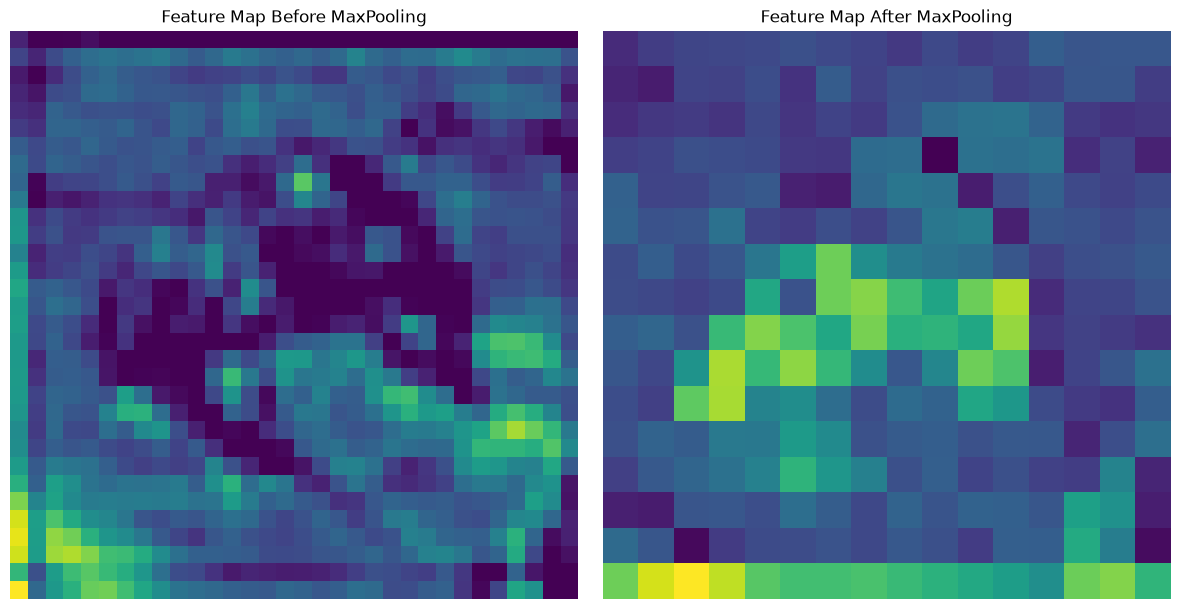

In [35]:
plt.figure(figsize=(12, 6))

# Before pooling
plt.subplot(1, 2, 1)
plt.imshow(feature_maps[0, :, :, 0], cmap="viridis")
plt.title("Feature Map Before MaxPooling")
plt.axis("off")

# After pooling
plt.subplot(1, 2, 2)
plt.imshow(maxpool_output[0, :, :, 0], cmap="viridis")
plt.title("Feature Map After MaxPooling")
plt.axis("off")

plt.tight_layout()
plt.show()

Display All 16 MaxPooled Feature Maps

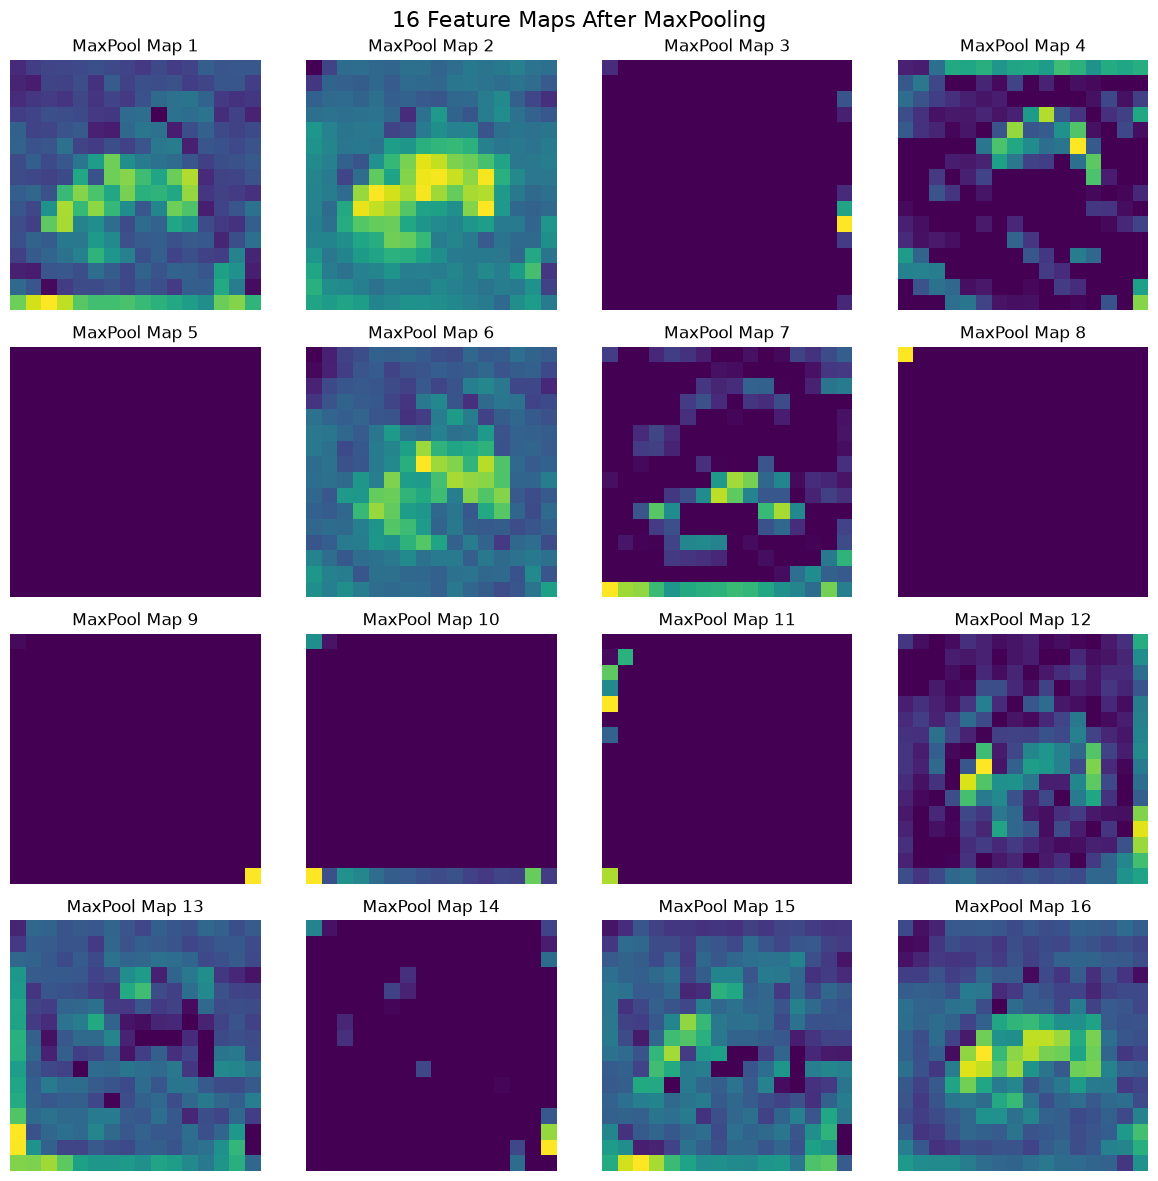

In [36]:
plt.figure(figsize=(12, 12))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        maxpool_output[0, :, :, i],
        cmap="viridis"
    )
    plt.title(f"MaxPool Map {i + 1}")
    plt.axis("off")

plt.suptitle(
    "16 Feature Maps After MaxPooling",
    fontsize=16
)

plt.tight_layout()
plt.show()

AveragePooling
Now repeat the same thing with AveragePooling.

In [37]:
avgpool_model = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    
    keras.layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    keras.layers.AveragePooling2D(
        pool_size=(2, 2)
    )
])

avgpool_output = avgpool_model.predict(
    sample_image,
    verbose=0
)

print("Before AveragePooling:", feature_maps.shape)
print("After AveragePooling :", avgpool_output.shape)

Before AveragePooling: (1, 32, 32, 16)
After AveragePooling : (1, 16, 16, 16)


A3.1.5 — Visualize AveragePooling

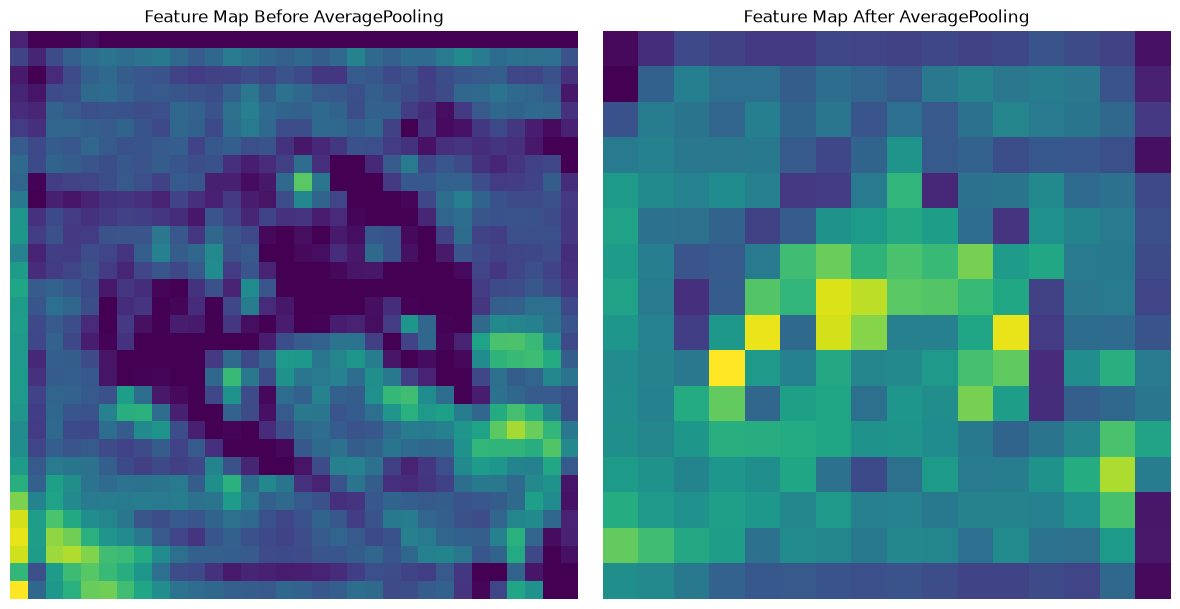

In [38]:
plt.figure(figsize=(12, 6))

# Before pooling
plt.subplot(1, 2, 1)
plt.imshow(feature_maps[0, :, :, 0], cmap="viridis")
plt.title("Feature Map Before AveragePooling")
plt.axis("off")

# After pooling
plt.subplot(1, 2, 2)
plt.imshow(avgpool_output[0, :, :, 0], cmap="viridis")
plt.title("Feature Map After AveragePooling")
plt.axis("off")

plt.tight_layout()
plt.show()

## MaxPooling vs AveragePooling

### MaxPooling2D

`MaxPooling2D(2,2)` divides the feature map into 2×2 regions and selects the maximum value from each region.

The maximum value represents the strongest activation in that region, so MaxPooling tends to retain the most prominent detected feature.

It also provides some degree of translation invariance because a small movement of a feature may still leave a strong activation within the same pooling region.

### AveragePooling2D

`AveragePooling2D(2,2)` calculates the mean value of each 2×2 region.

Unlike MaxPooling, it does not select only the strongest activation. Instead, it produces a smoother representation and can preserve more overall spatial information, although the resulting features are generally less sharp.

### Global Average Pooling

Modern CNN architectures often use `GlobalAveragePooling2D` instead of `Flatten`.

GlobalAveragePooling2D averages each complete feature map into a single value.

For example:

`16 × 16 × 128`

becomes:

`128`

This dramatically reduces the number of parameters before the Dense classification layer and can therefore reduce overfitting.

In [39]:
flatten_model = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    
    keras.layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    keras.layers.MaxPooling2D(
        (2, 2)
    ),
    
    keras.layers.Flatten()
])

print(flatten_model.summary())

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448 (1.75 KB)

 Trainable params: 448 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

None


## Flatten Layer

The `Flatten` layer converts a 3D feature tensor containing height, width, and channels `(H, W, C)` into a single one-dimensional vector.

For this example:

16 × 16 × 16 = 4096

Therefore:

`(None, 16, 16, 16)` → `(None, 4096)`

The flattened vector can then be connected to Dense layers for classification.

The flattened size directly affects the number of parameters in the first Dense layer. For example, connecting 4096 flattened values to a Dense layer containing 256 neurons requires:

4096 × 256 + 256 = 1,048,832 parameters.

Therefore, reducing the spatial dimensions before Flatten is important for keeping the model size manageable.

LeNet-5 Architecture

In [40]:
lenet5 = keras.Sequential([
    
    keras.layers.Input(shape=(32, 32, 3)),
    
    keras.layers.Conv2D(
        6,
        (5, 5),
        activation="tanh"
    ),
    
    keras.layers.AveragePooling2D(
        (2, 2)
    ),
    
    keras.layers.Conv2D(
        16,
        (5, 5),
        activation="tanh"
    ),
    
    keras.layers.AveragePooling2D(
        (2, 2)
    ),
    
    keras.layers.Flatten(),
    
    keras.layers.Dense(
        120,
        activation="tanh"
    ),
    
    keras.layers.Dense(
        84,
        activation="tanh"
    ),
    
    keras.layers.Dense(
        10,
        activation="softmax"
    )
])

lenet5.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

## LeNet-5 Architecture

LeNet-5, introduced by Yann LeCun and colleagues in 1998, was one of the pioneering successful convolutional neural network architectures. It was designed for handwritten digit and character recognition tasks.

For this project, the architecture is adapted for CIFAR-10 by using a 32×32×3 RGB input and a 10-class output.

The architecture follows:

Input → Conv → Average Pool → Conv → Average Pool → Flatten → Dense → Dense → Output

LeNet-5 established the fundamental Conv → Pool → Conv → Pool → Dense pattern that influenced later CNN architectures.

Compared with modern CNNs, this architecture uses:

- `tanh` activation instead of ReLU
- AveragePooling instead of MaxPooling
- 5×5 convolution filters instead of commonly used stacked 3×3 filters

### Manual Parameter Calculation

For the first Conv2D layer:

5 × 5 × 3 × 6 + 6 = 456 parameters

For the first Dense layer:

400 × 120 + 120 = 48,120 parameters

The bias term is added because each filter or neuron has one trainable bias.

Custom CNN Baseline
Now comes the actual CNN we will eventually train.

In [41]:
cnn_model = keras.Sequential([
    
    keras.layers.Input(shape=(32, 32, 3)),
    
    # Block 1
    keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    keras.layers.MaxPooling2D(
        (2, 2)
    ),
    
    # Block 2
    keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    keras.layers.MaxPooling2D(
        (2, 2)
    ),
    
    # Block 3
    keras.layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    
    # Classification head
    keras.layers.GlobalAveragePooling2D(),
    
    keras.layers.Dense(
        256,
        activation="relu"
    ),
    
    keras.layers.Dense(
        10,
        activation="softmax"
    )
])

cnn_model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

Check Parameter Count

In [42]:
total_params = cnn_model.count_params()

print("Total parameters:", total_params)
print("Less than 2 million:", total_params < 2_000_000)

Total parameters: 175018
Less than 2 million: True


In [43]:
print(f"Total parameters: {total_params:,}")

Total parameters: 175,018


## Custom CNN Baseline

The custom CNN uses three convolutional stages.

The first two convolutional blocks contain two 3×3 convolution layers before pooling. The first convolution can learn simple low-level features such as edges and gradients, while the second convolution combines these features into more complex patterns such as textures and simple shapes.

Pooling is then used to reduce the spatial resolution and computational cost.

The number of filters increases with depth:

32 → 64 → 128

This allows deeper layers to learn increasingly rich feature representations.

`GlobalAveragePooling2D` is used instead of `Flatten` to reduce the number of parameters in the classification head. Each feature map is reduced to one average value, producing a compact representation before the Dense layers.

The final Dense layer contains 10 neurons because CIFAR-10 contains 10 classes. Softmax converts the outputs into class probabilities.

## A4.1 — Backpropagation in CNN

### Forward Pass
The input image passes through convolution layers where learnable kernels extract features. Activation functions such as ReLU introduce non-linearity, and pooling reduces spatial dimensions. The process continues through deeper convolution layers, followed by GlobalAveragePooling/Dense layers and a final Softmax layer. The predicted probabilities are compared with the true labels using categorical cross-entropy to calculate the loss.

### Backward Pass
During backpropagation, the loss gradient flows backward through the network. For Dense layers, the gradient calculation is similar to an MLP. For convolution layers, the gradients with respect to the kernel weights are calculated using the upstream gradient and the corresponding local input patches.

### Pooling Gradients
In MaxPooling, only the position containing the maximum value receives the gradient; the other positions receive zero. This is called the max-location switch or max-index mask.

In AveragePooling, the upstream gradient is distributed equally among all positions in the pooling window.

### Flatten
The Flatten layer only reshapes the feature tensor into a 1D vector, so its backward operation simply reshapes the gradient back to the original 3D feature-map dimensions.

In [44]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Use the CNN created in A3
model_cnn = cnn_model

model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

es = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

rlrop = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history = model_cnn.fit(
    X_train,
    y_train_ohe,
    epochs=2,
    batch_size=64,
    validation_split=0.1,
    callbacks=[es, rlrop]
)

Epoch 1/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 111ms/step - accuracy: 0.3370 - loss: 1.7529 - val_accuracy: 0.4500 - val_loss: 1.4589 - learning_rate: 0.0010
Epoch 2/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 84s 120ms/step - accuracy: 0.5223 - loss: 1.3072 - val_accuracy: 0.5314 - val_loss: 1.2944 - learning_rate: 0.0010


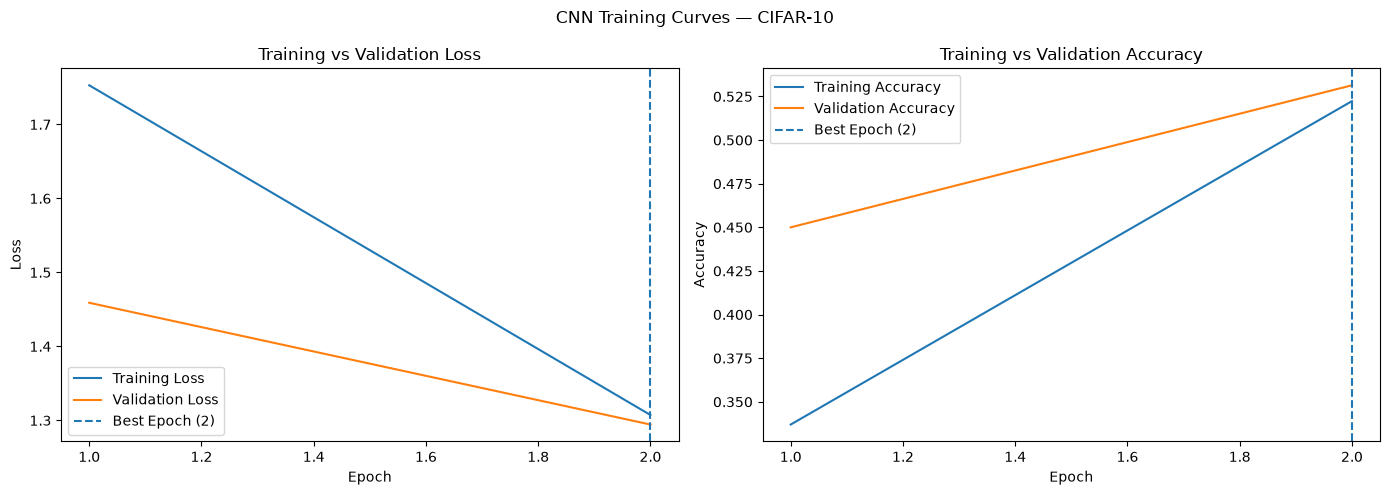

Final Training Accuracy: 0.5223
Final Validation Accuracy: 0.5314
Best Validation Accuracy: 0.5314
Best Epoch: 2


In [45]:
import matplotlib.pyplot as plt
import numpy as np

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]
train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

epochs = np.arange(1, len(train_loss) + 1)

best_epoch = np.argmin(val_loss) + 1

plt.figure(figsize=(14, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.axvline(best_epoch, linestyle="--", label=f"Best Epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, train_acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")
plt.axvline(best_epoch, linestyle="--", label=f"Best Epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.suptitle("CNN Training Curves — CIFAR-10")
plt.tight_layout()
plt.show()

print(f"Final Training Accuracy: {train_acc[-1]:.4f}")
print(f"Final Validation Accuracy: {val_acc[-1]:.4f}")
print(f"Best Validation Accuracy: {max(val_acc):.4f}")
print(f"Best Epoch: {np.argmax(val_acc) + 1}")

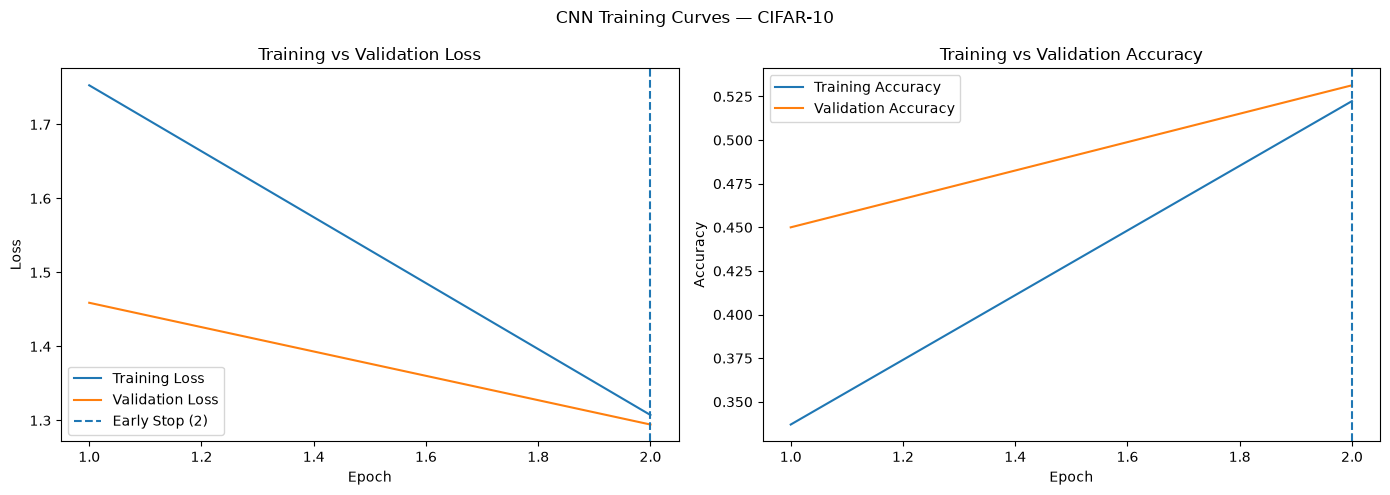

Final Train Accuracy: 0.5223
Final Validation Accuracy: 0.5314


In [46]:
plt.figure(figsize=(14, 5))

# Find LR reduction epochs from the training log if available
lr_changes = []

for i in range(1, len(history.history["learning_rate"])):
    if history.history["learning_rate"][i] < history.history["learning_rate"][i-1]:
        lr_changes.append(i + 1)

stop_epoch = len(history.history["loss"])

plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")

for e in lr_changes:
    plt.axvline(e, linestyle="--", label=f"LR ↓ Epoch {e}")

plt.axvline(
    stop_epoch,
    linestyle="--",
    label=f"Early Stop ({stop_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, train_acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")

for e in lr_changes:
    plt.axvline(e, linestyle="--")

plt.axvline(stop_epoch, linestyle="--")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.suptitle("CNN Training Curves — CIFAR-10")
plt.tight_layout()
plt.show()

print("Final Train Accuracy:", f"{train_acc[-1]:.4f}")
print("Final Validation Accuracy:", f"{val_acc[-1]:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.5260 - loss: 1.3140

Test Accuracy: 0.5260


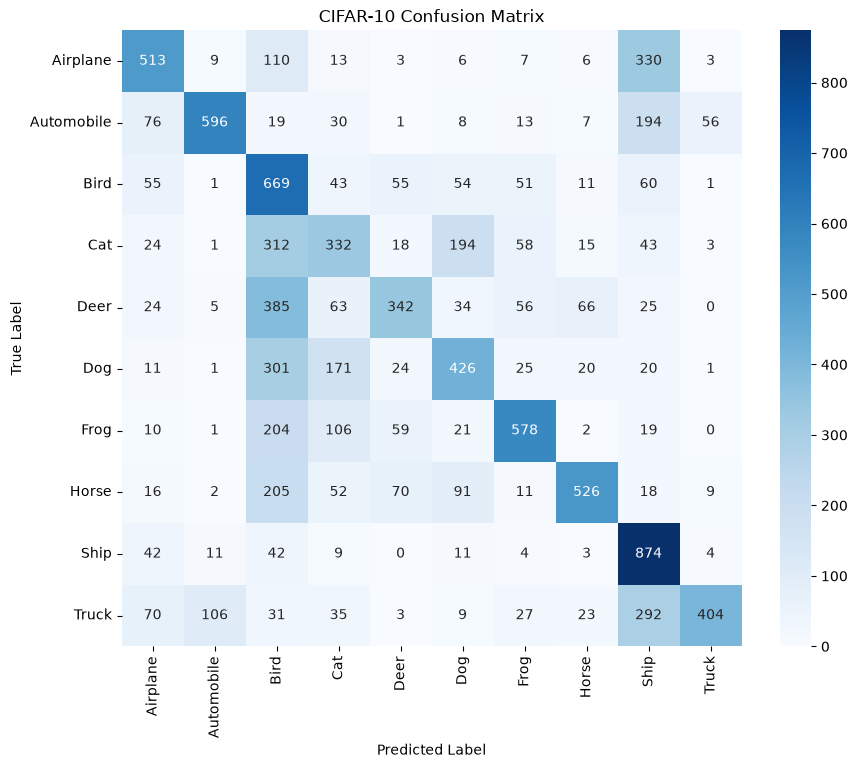

In [47]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Evaluate
test_loss, test_accuracy = model_cnn.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

print(f"\nTest Accuracy: {test_accuracy:.4f}")

# Predictions
y_pred_prob = model_cnn.predict(X_test, verbose=0)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test_ohe, axis=1)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CIFAR-10 Confusion Matrix")
plt.show()

In [48]:
# Remove diagonal because correct predictions are not confusion
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

top_pairs = []

for _ in range(3):
    i, j = np.unravel_index(
        np.argmax(cm_no_diag),
        cm_no_diag.shape
    )
    
    top_pairs.append(
        (class_names[i], class_names[j], cm_no_diag[i, j])
    )
    
    cm_no_diag[i, j] = 0

print("\nTop 3 confused class pairs:")

for true_class, predicted_class, count in top_pairs:
    print(
        f"{true_class} → {predicted_class}: {count} images"
    )


Top 3 confused class pairs:
Deer → Bird: 385 images
Airplane → Ship: 330 images
Cat → Bird: 312 images


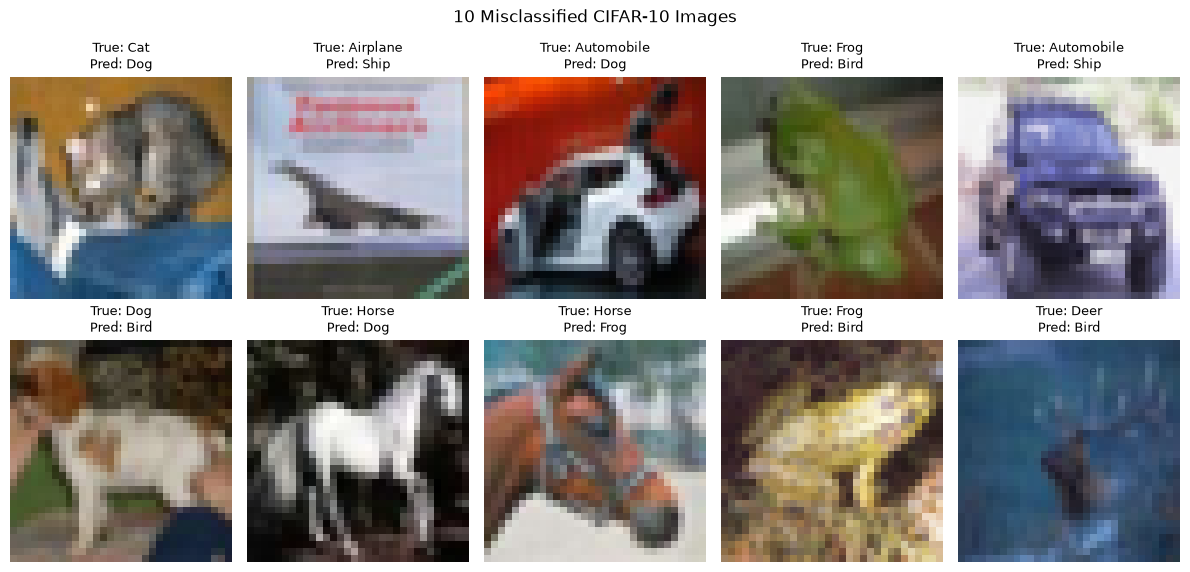

In [49]:
misclassified = np.where(y_true != y_pred)[0]

plt.figure(figsize=(12, 6))

for i, idx in enumerate(misclassified[:10]):
    
    plt.subplot(2, 5, i + 1)
    
    plt.imshow(X_test[idx])
    
    plt.title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}",
        fontsize=9
    )
    
    plt.axis("off")

plt.suptitle("10 Misclassified CIFAR-10 Images")
plt.tight_layout()
plt.show()

## Error Analysis

The CNN is expected to make more mistakes between visually similar classes such as Cat vs Dog and Automobile vs Truck.

CIFAR-10 images are only 32×32 pixels, so fine visual details are limited. Cats and dogs can have similar shapes, colours, and backgrounds, while automobiles and trucks can have similar body structures.

In contrast, classes such as airplanes and ships often have more distinguishable global shapes and visual structures.

Therefore, classification errors are not distributed equally across all classes. The confusion matrix helps identify which class pairs are most difficult for the trained CNN.

## A4.1 — Backpropagation in CNN

### Forward Pass
During the forward pass, the input image passes through convolution layers, where learnable kernels extract features. Activation functions such as ReLU introduce non-linearity, and pooling reduces spatial dimensions. This process is repeated through deeper layers, followed by Flatten or GlobalAveragePooling, Dense layers, and Softmax. The predicted probabilities are compared with the true labels using categorical cross-entropy to calculate the loss.

### Backward Pass
During backpropagation, gradients flow backward from the loss toward the earlier layers. For Dense layers, the gradient calculation is similar to backpropagation in an MLP. For convolution layers, the gradient with respect to each kernel weight is calculated using the upstream gradient and the corresponding local input patches.

### MaxPooling Gradient
In MaxPooling, only the position that produced the maximum value during the forward pass receives the full gradient. All other positions receive zero gradient. This is called the max-location switch or max-index mask.

### AveragePooling Gradient
In AveragePooling, the upstream gradient is distributed equally among all positions in the pooling window.

### Flatten Gradient
Flatten does not perform mathematical feature extraction. It only reshapes the 3D tensor into a 1D vector. During backpropagation, the gradient is simply reshaped back to the original 3D dimensions.

In [55]:
model_cnn = cnn_model

## A4.1 — Backpropagation in CNN

### Forward Pass
During the forward pass, the input image passes through convolution layers, where learnable kernels extract features. Activation functions such as ReLU introduce non-linearity, and pooling reduces spatial dimensions. This process is repeated through deeper layers, followed by Flatten or GlobalAveragePooling, Dense layers, and Softmax. The predicted probabilities are compared with the true labels using categorical cross-entropy to calculate the loss.

### Backward Pass
During backpropagation, gradients flow backward from the loss toward the earlier layers. For Dense layers, the gradient calculation is similar to backpropagation in an MLP. For convolution layers, the gradient with respect to each kernel weight is calculated using the upstream gradient and the corresponding local input patches.

### MaxPooling Gradient
In MaxPooling, only the position that produced the maximum value during the forward pass receives the full gradient. All other positions receive zero gradient. This is called the max-location switch or max-index mask.

### AveragePooling Gradient
In AveragePooling, the upstream gradient is distributed equally among all positions in the pooling window.

### Flatten Gradient
Flatten does not perform mathematical feature extraction. It only reshapes the 3D tensor into a 1D vector. During backpropagation, the gradient is simply reshaped back to the original 3D dimensions.

In [57]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Use the CNN created in A3
model_cnn = cnn_model

model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

es = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

rlrop = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history = model_cnn.fit(
    X_train,
    y_train_ohe,
    epochs=2,
    batch_size=64,
    validation_split=0.1,
    callbacks=[es, rlrop]
)

Epoch 1/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 86s 113ms/step - accuracy: 0.7196 - loss: 0.7912 - val_accuracy: 0.7170 - val_loss: 0.8403 - learning_rate: 0.0010
Epoch 2/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 79s 112ms/step - accuracy: 0.7426 - loss: 0.7249 - val_accuracy: 0.7332 - val_loss: 0.7800 - learning_rate: 0.0010


## A4.2 — Learning Rate Scheduling

`ReduceLROnPlateau` monitors validation loss. When the validation loss stops improving, it reduces the learning rate by half.

This allows the CNN to first learn using a relatively larger learning rate and later make smaller, more precise weight updates when approaching a better solution.

`EarlyStopping` stops training when validation loss does not improve for 10 consecutive epochs and restores the weights from the best-performing epoch.

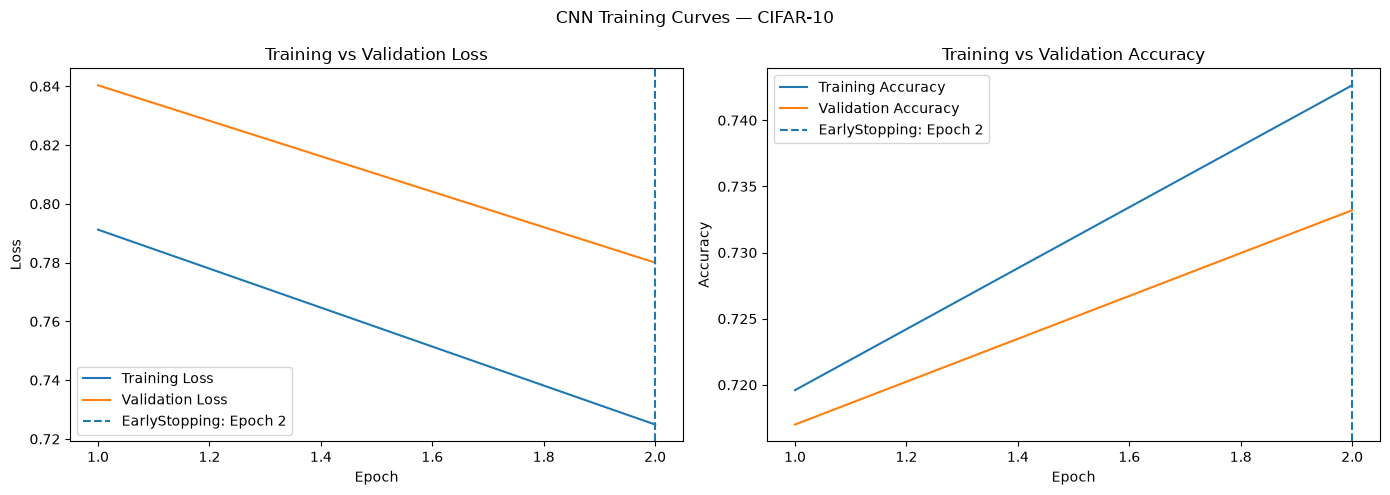

Final Train Accuracy: 0.7426
Final Validation Accuracy: 0.7332
Best Validation Accuracy: 0.7332


In [58]:
import numpy as np
import matplotlib.pyplot as plt

loss = history.history["loss"]
val_loss = history.history["val_loss"]
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

epochs = np.arange(1, len(loss) + 1)

# Detect epochs where learning rate decreased
lr = history.history.get("learning_rate", [])
lr_epochs = []

for i in range(1, len(lr)):
    if lr[i] < lr[i - 1]:
        lr_epochs.append(i + 1)

# Training stopped at the final recorded epoch
stop_epoch = len(loss)

plt.figure(figsize=(14, 5))

# -------- Loss --------
plt.subplot(1, 2, 1)

plt.plot(epochs, loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")

# Early stopping line
plt.axvline(
    stop_epoch,
    linestyle="--",
    label=f"EarlyStopping: Epoch {stop_epoch}"
)

# LR reduction lines
for e in lr_epochs:
    plt.axvline(
        e,
        linestyle="--",
        label=f"LR reduced: Epoch {e}"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

# -------- Accuracy --------
plt.subplot(1, 2, 2)

plt.plot(epochs, acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")

plt.axvline(
    stop_epoch,
    linestyle="--",
    label=f"EarlyStopping: Epoch {stop_epoch}"
)

for e in lr_epochs:
    plt.axvline(e, linestyle="--")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.suptitle("CNN Training Curves — CIFAR-10")

plt.tight_layout()
plt.show()

# Final values
print(f"Final Train Accuracy: {acc[-1]:.4f}")
print(f"Final Validation Accuracy: {val_acc[-1]:.4f}")
print(f"Best Validation Accuracy: {max(val_acc):.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.7243 - loss: 0.8058

Test Accuracy: 0.7243


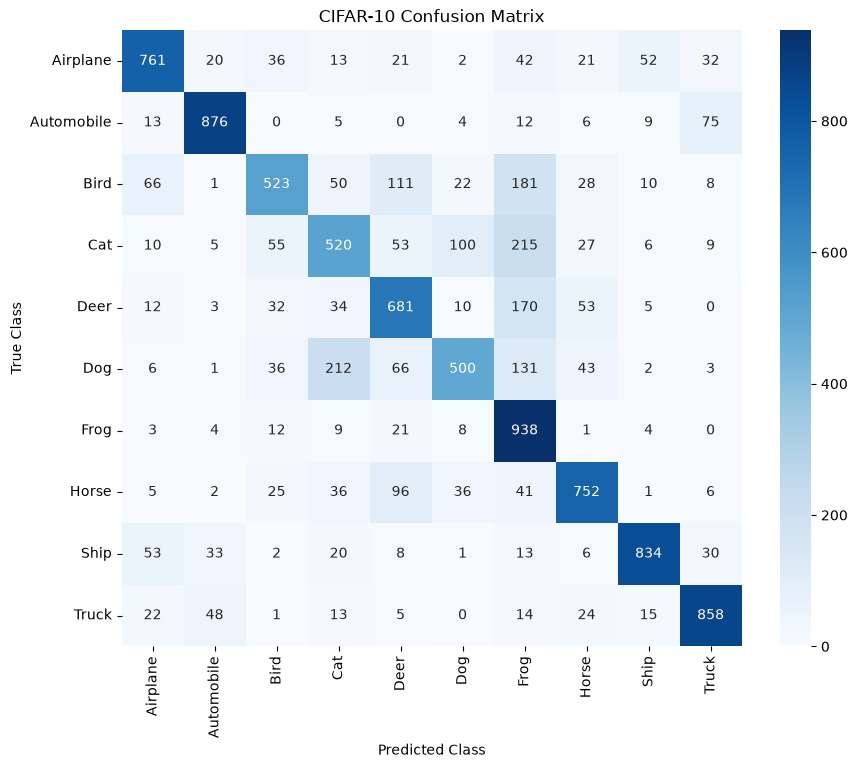


Top 3 Most-Confused Class Pairs:
1. Cat → Frog : 215 images
2. Dog → Cat : 212 images
3. Bird → Frog : 181 images


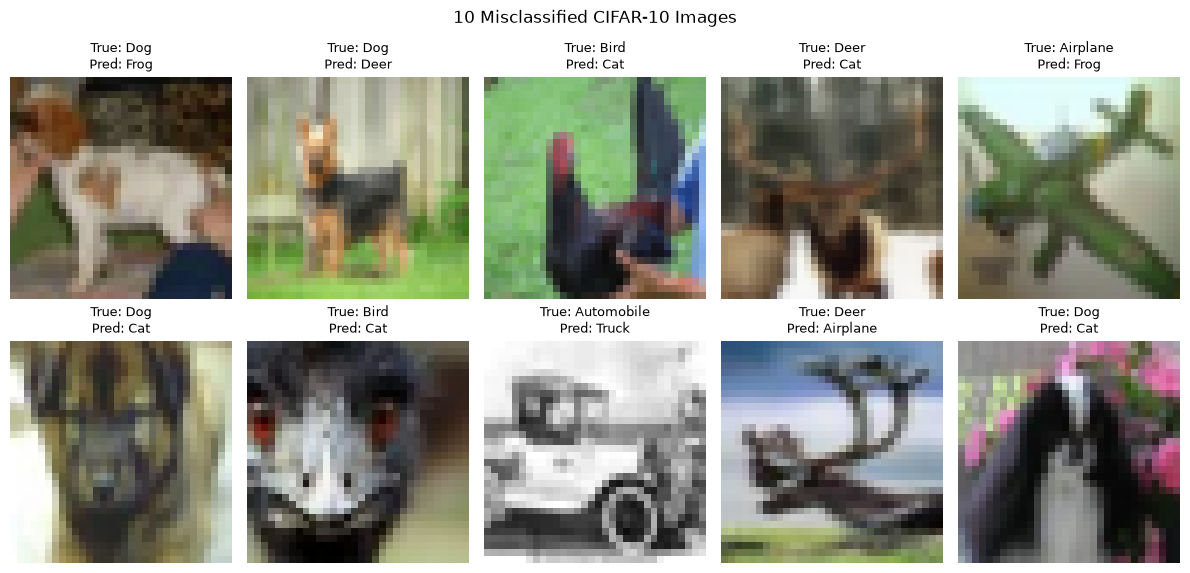

In [59]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Evaluate model
test_loss, test_accuracy = model_cnn.evaluate(
    X_test,
    y_test_ohe,
    verbose=1
)

print(f"\nTest Accuracy: {test_accuracy:.4f}")

# Predictions
y_pred_prob = model_cnn.predict(X_test, verbose=0)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test_ohe, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("CIFAR-10 Confusion Matrix")
plt.show()

# -------- Top 3 Confused Pairs --------
cm_temp = cm.copy()
np.fill_diagonal(cm_temp, 0)

print("\nTop 3 Most-Confused Class Pairs:")

for rank in range(3):
    i, j = np.unravel_index(
        np.argmax(cm_temp),
        cm_temp.shape
    )

    print(
        f"{rank + 1}. {class_names[i]} → "
        f"{class_names[j]} : {cm_temp[i, j]} images"
    )

    cm_temp[i, j] = 0

# -------- 10 Misclassified Images --------
misclassified = np.where(y_true != y_pred)[0]

plt.figure(figsize=(12, 6))

for i, idx in enumerate(misclassified[:10]):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[idx])

    plt.title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle("10 Misclassified CIFAR-10 Images")
plt.tight_layout()
plt.show()

## A4.4 — Error Analysis

The CNN may confuse visually similar classes such as Cat and Dog or Automobile and Truck more frequently than visually distinct classes such as Airplane and Ship.

CIFAR-10 images have a resolution of only 32×32 pixels. This low resolution removes many fine-grained visual details that could help distinguish similar objects.

For example, a cat and dog may have similar body shapes, colours, and backgrounds. Similarly, automobiles and trucks can have overlapping shapes and appearances.

The confusion matrix shows these class-level errors, while the misclassified images provide visual examples of cases where the CNN predicted the wrong class.

## A5.1 — Why Data Augmentation?

A CNN with millions of parameters trained on only 50,000 CIFAR-10 images can memorize the training data and overfit.

Data augmentation artificially increases the effective variety of the training data by applying random transformations such as rotation, shifting, zooming, and horizontal flipping.

The model sees a slightly different version of an image during different training epochs. This acts as a regularizer and helps the model learn general features instead of memorizing individual training examples.

Data augmentation is particularly useful for relatively small image datasets and is widely used in computer vision applications.

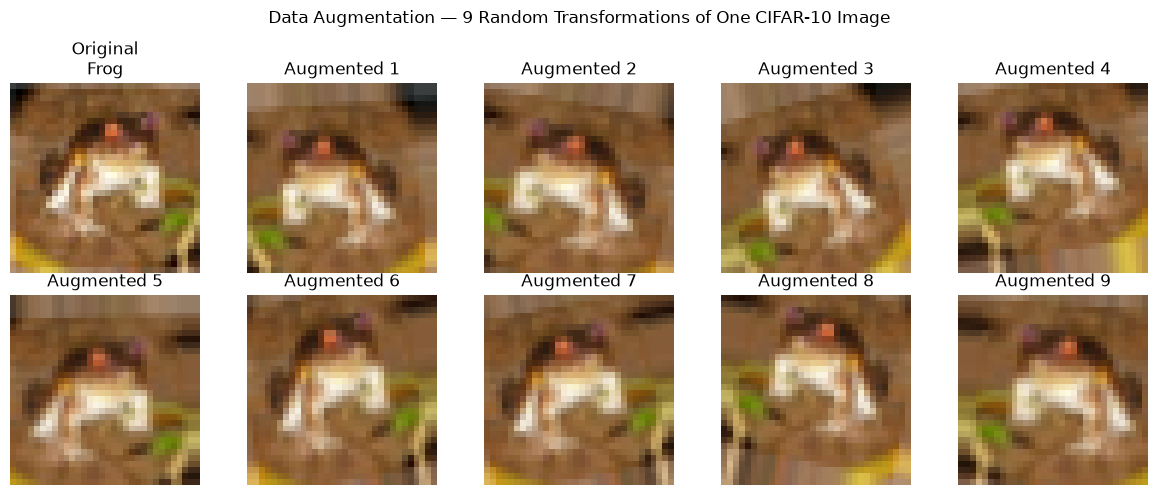

In [61]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode="nearest"
)

datagen.fit(X_train)

# Generate 9 augmented versions of one image
img = X_train[0]

augmented_images = datagen.flow(
    img[np.newaxis, ...],
    batch_size=1,
    shuffle=False
)

plt.figure(figsize=(12, 5))

# Original
plt.subplot(2, 5, 1)
plt.imshow(img)
plt.title(f"Original\n{class_names[y_train[0][0]]}")
plt.axis("off")

# 9 augmented images
for i in range(9):
    aug_img = next(augmented_images)[0]

    plt.subplot(2, 5, i + 2)
    plt.imshow(np.clip(aug_img, 0, 1))
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.suptitle(
    "Data Augmentation — 9 Random Transformations of One CIFAR-10 Image"
)

plt.tight_layout()
plt.show()

In [63]:
def build_cnn():
    return keras.Sequential([
        keras.layers.Input(shape=(32, 32, 3)),

        keras.layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),
        keras.layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),
        keras.layers.MaxPooling2D((2, 2)),

        keras.layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),
        keras.layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),
        keras.layers.MaxPooling2D((2, 2)),

        keras.layers.Conv2D(
            128, (3, 3),
            activation="relu",
            padding="same"
        ),

        keras.layers.GlobalAveragePooling2D(),

        keras.layers.Dense(256, activation="relu"),
        keras.layers.Dense(10, activation="softmax")
    ])


model_aug = build_cnn()

model_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

es_aug = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

rlrop_aug = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history_aug = model_aug.fit(
    datagen.flow(
        X_train,
        y_train_ohe,
        batch_size=64
    ),
    epochs=2,
    validation_data=(X_test, y_test_ohe),
    callbacks=[es_aug, rlrop_aug]
)

Epoch 1/2
782/782 ━━━━━━━━━━━━━━━━━━━━ 101s 124ms/step - accuracy: 0.3096 - loss: 1.8177 - val_accuracy: 0.4297 - val_loss: 1.5492 - learning_rate: 0.0010
Epoch 2/2
782/782 ━━━━━━━━━━━━━━━━━━━━ 96s 122ms/step - accuracy: 0.4848 - loss: 1.4034 - val_accuracy: 0.5149 - val_loss: 1.3448 - learning_rate: 0.0010


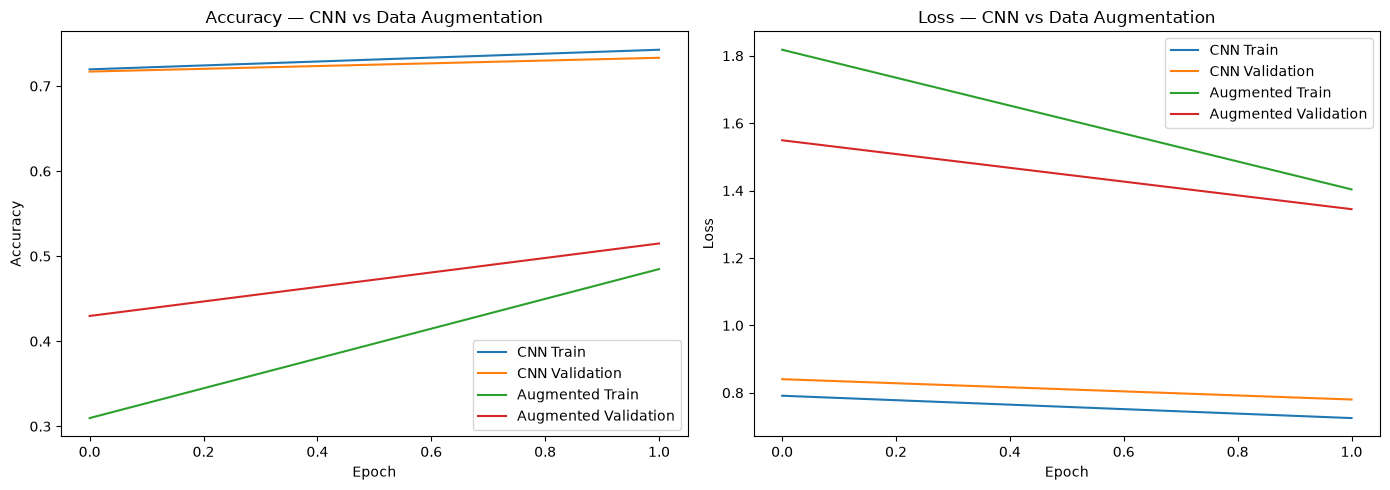

In [64]:
plt.figure(figsize=(14, 5))

# Accuracy comparison
plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="CNN Train"
)

plt.plot(
    history.history["val_accuracy"],
    label="CNN Validation"
)

plt.plot(
    history_aug.history["accuracy"],
    label="Augmented Train"
)

plt.plot(
    history_aug.history["val_accuracy"],
    label="Augmented Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy — CNN vs Data Augmentation")
plt.legend()


# Loss comparison
plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="CNN Train"
)

plt.plot(
    history.history["val_loss"],
    label="CNN Validation"
)

plt.plot(
    history_aug.history["loss"],
    label="Augmented Train"
)

plt.plot(
    history_aug.history["val_loss"],
    label="Augmented Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss — CNN vs Data Augmentation")
plt.legend()

plt.tight_layout()
plt.show()

## A5.3 — Effect of Data Augmentation

Data augmentation acts as a regularizer and can reduce overfitting.

The augmented model is expected to have a smaller gap between training and validation accuracy compared with the model trained without augmentation.

Training accuracy may be slightly lower because the model is trained on continuously transformed and therefore more difficult examples.

The main objective is better generalization to unseen images, which can result in improved test accuracy.

In [66]:
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")


model_modern_aug = keras.Sequential([
    data_augmentation,

    keras.layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    keras.layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    keras.layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),

    keras.layers.GlobalAveragePooling2D(),

    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

model_modern_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_modern = model_modern_aug.fit(
    X_train,
    y_train_ohe,
    epochs=2,
    batch_size=64,
    validation_split=0.1,
    callbacks=[es_aug, rlrop_aug]
)

Epoch 1/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 76s 102ms/step - accuracy: 0.2974 - loss: 1.8559 - val_accuracy: 0.4212 - val_loss: 1.5470 - learning_rate: 0.0010
Epoch 2/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 76s 108ms/step - accuracy: 0.4329 - loss: 1.5467 - val_accuracy: 0.4836 - val_loss: 1.4367 - learning_rate: 0.0010


In [67]:
# Evaluate all three models on untouched test data

_, baseline_test_acc = model_cnn.evaluate(
    X_test,
    y_test_ohe,
    verbose=0
)

_, generator_test_acc = model_aug.evaluate(
    X_test,
    y_test_ohe,
    verbose=0
)

_, modern_test_acc = model_modern_aug.evaluate(
    X_test,
    y_test_ohe,
    verbose=0
)

print("\nTest Accuracy Comparison")
print("-" * 35)
print(f"Original CNN       : {baseline_test_acc:.4f}")
print(f"ImageDataGenerator : {generator_test_acc:.4f}")
print(f"Keras Augmentation : {modern_test_acc:.4f}")


Test Accuracy Comparison
-----------------------------------
Original CNN       : 0.7243
ImageDataGenerator : 0.5149
Keras Augmentation : 0.4802


## A6.1 — Why Transfer Learning?

Training a deep CNN from scratch requires substantial computational time and data. Transfer Learning starts with a model that has already been trained on a large dataset such as ImageNet, which contains millions of images across 1,000 classes.

A pre-trained CNN has already learned a hierarchy of visual features such as edges, textures, shapes, and object parts. These features can often be reused for a new image-classification task.

Two common strategies are:

### 1. Feature Extraction
The pre-trained base model is frozen, meaning its weights are not updated. A new classification head is added and only the new head is trained.

Advantages:
- Fast training
- Fewer trainable parameters
- Lower computational cost

### 2. Fine-Tuning
Some of the upper layers of the pre-trained model are unfrozen and trained together with the new classification head using a very small learning rate.

Fine-tuning is slower but can adapt the learned features more closely to the new dataset.

In [68]:
import tensorflow as tf

# Resize CIFAR-10 images for MobileNetV2
X_train_r = tf.image.resize(X_train, (96, 96))
X_test_r = tf.image.resize(X_test, (96, 96))

print("Original shape:", X_train.shape)
print("Resized shape :", X_train_r.shape)

Original shape: (50000, 32, 32, 3)
Resized shape : (50000, 96, 96, 3)


In [69]:
base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = keras.Input(shape=(96, 96, 3))

x = base_model(
    inputs,
    training=False
)

x = keras.layers.GlobalAveragePooling2D()(x)

x = keras.layers.Dense(
    128,
    activation="relu"
)(x)

outputs = keras.layers.Dense(
    10,
    activation="softmax"
)(x)

model_fe = keras.Model(
    inputs,
    outputs
)

model_fe.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 102s 11us/step


Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_18 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [70]:
print("Total parameters:", f"{model_fe.count_params():,}")

trainable_params = np.sum([
    np.prod(v.shape)
    for v in model_fe.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in model_fe.non_trainable_weights
])

print("Trainable parameters:", f"{trainable_params:,}")
print("Non-trainable parameters:", f"{non_trainable_params:,}")

Total parameters: 2,423,242
Trainable parameters: 165,258
Non-trainable parameters: 2,257,984


In [72]:
model_fe.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


history_fe = model_fe.fit(
    X_train_r,
    y_train_ohe,
    epochs=2,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 370s 515ms/step - accuracy: 0.7592 - loss: 0.6962 - val_accuracy: 0.7896 - val_loss: 0.6055
Epoch 2/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 373s 529ms/step - accuracy: 0.8053 - loss: 0.5525 - val_accuracy: 0.7922 - val_loss: 0.5727


In [73]:
fe_loss, fe_accuracy = model_fe.evaluate(
    X_test_r,
    y_test_ohe,
    verbose=1
)

print(f"MobileNetV2 Feature Extraction Test Accuracy: {fe_accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 94s 297ms/step - accuracy: 0.7987 - loss: 0.5848
MobileNetV2 Feature Extraction Test Accuracy: 0.7987


In [74]:
test_acc_fe = fe_accuracy

In [77]:
# Unfreeze MobileNetV2
base_model.trainable = True

# Freeze all layers except the top 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with very small learning rate
model_fe.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_ft = model_fe.fit(
    X_train_r,
    y_train_ohe,
    epochs=1,
    batch_size=32,
    validation_split=0.1
)

ft_loss, ft_accuracy = model_fe.evaluate(
    X_test_r,
    y_test_ohe,
    verbose=1
)

test_acc_ft = ft_accuracy

print(
    f"MobileNetV2 Fine-Tuned Test Accuracy: "
    f"{ft_accuracy:.4f}"
)

1407/1407 ━━━━━━━━━━━━━━━━━━━━ 523s 360ms/step - accuracy: 0.7850 - loss: 0.6303 - val_accuracy: 0.8180 - val_loss: 0.5424
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 257ms/step - accuracy: 0.8164 - loss: 0.5508
MobileNetV2 Fine-Tuned Test Accuracy: 0.8164


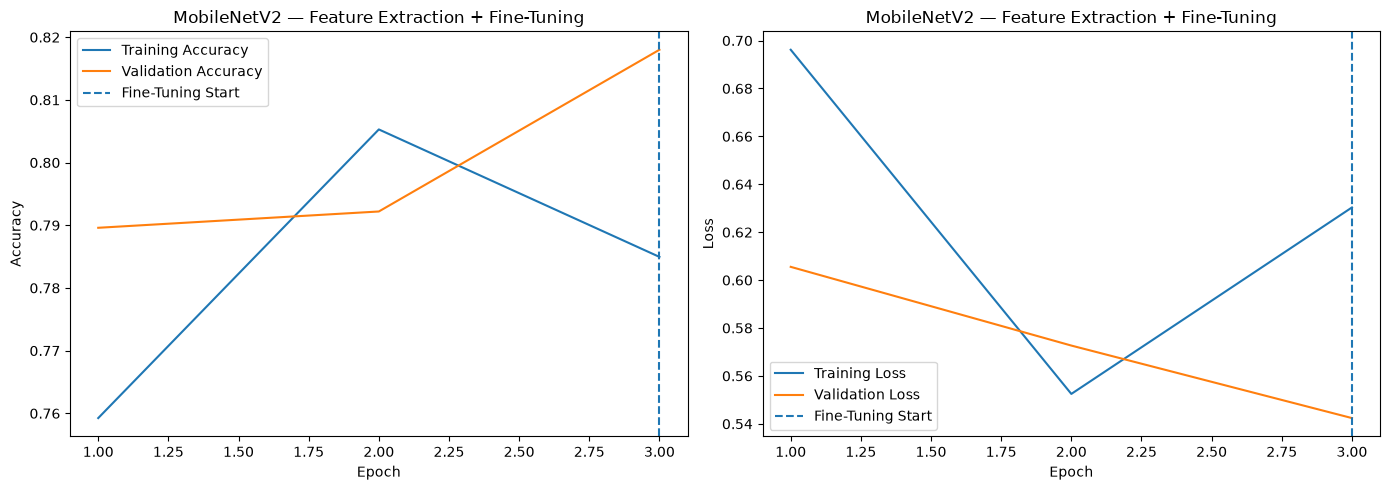

In [78]:
# Combine histories
fe_val_acc = history_fe.history["val_accuracy"]
ft_val_acc = history_ft.history["val_accuracy"]

fe_train_acc = history_fe.history["accuracy"]
ft_train_acc = history_ft.history["accuracy"]

fe_val_loss = history_fe.history["val_loss"]
ft_val_loss = history_ft.history["val_loss"]

fe_train_loss = history_fe.history["loss"]
ft_train_loss = history_ft.history["loss"]

combined_train_acc = fe_train_acc + ft_train_acc
combined_val_acc = fe_val_acc + ft_val_acc

combined_train_loss = fe_train_loss + ft_train_loss
combined_val_loss = fe_val_loss + ft_val_loss

epochs_combined = range(
    1,
    len(combined_train_acc) + 1
)

fine_tune_start = len(fe_train_acc) + 1

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs_combined,
    combined_train_acc,
    label="Training Accuracy"
)

plt.plot(
    epochs_combined,
    combined_val_acc,
    label="Validation Accuracy"
)

plt.axvline(
    fine_tune_start,
    linestyle="--",
    label="Fine-Tuning Start"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 — Feature Extraction + Fine-Tuning")
plt.legend()


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs_combined,
    combined_train_loss,
    label="Training Loss"
)

plt.plot(
    epochs_combined,
    combined_val_loss,
    label="Validation Loss"
)

plt.axvline(
    fine_tune_start,
    linestyle="--",
    label="Fine-Tuning Start"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 — Feature Extraction + Fine-Tuning")
plt.legend()

plt.tight_layout()
plt.show()

In [80]:
import pandas as pd

# Evaluate models if accuracy variables don't already exist

lenet5.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

_, lenet_acc = lenet5.evaluate(
    X_test,
    y_test_ohe,
    verbose=0
)

_, scratch_acc = model_cnn.evaluate(
    X_test,
    y_test_ohe,
    verbose=0
)

_, aug_acc = model_aug.evaluate(
    X_test,
    y_test_ohe,
    verbose=0
)

_, modern_aug_acc = model_modern_aug.evaluate(
    X_test,
    y_test_ohe,
    verbose=0
)

results = pd.DataFrame({
    "Model": [
        "LeNet-5",
        "CNN Scratch No Aug",
        "CNN Scratch + Aug",
        "CNN + Keras Aug Layers",
        "MobileNetV2 Feature Extraction",
        "MobileNetV2 Fine-Tuned"
    ],

    "Architecture": [
        "LeNet-5",
        "Custom CNN",
        "Custom CNN",
        "Custom CNN",
        "MobileNetV2",
        "MobileNetV2"
    ],

    "Augmentation": [
        "No",
        "No",
        "ImageDataGenerator",
        "Keras Layers",
        "No",
        "No"
    ],

    "Transfer Learning": [
        "No",
        "No",
        "No",
        "No",
        "Feature Extraction",
        "Fine-Tuning"
    ],

    "Test Accuracy": [
        lenet_acc,
        scratch_acc,
        aug_acc,
        modern_aug_acc,
        test_acc_fe,
        test_acc_ft
    ],

    "Parameters": [
        lenet5.count_params(),
        model_cnn.count_params(),
        model_aug.count_params(),
        model_modern_aug.count_params(),
        model_fe.count_params(),
        model_fe.count_params()
    ]
})

display(
    results.style.highlight_max(
        subset=["Test Accuracy"],
        color="lightgreen"
    ).format({
        "Test Accuracy": "{:.4f}",
        "Parameters": "{:,}"
    })
)

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy,Parameters
0,LeNet-5,LeNet-5,No,No,0.0959,"62,006"
1,CNN Scratch No Aug,Custom CNN,No,No,0.7243,"175,018"
2,CNN Scratch + Aug,Custom CNN,ImageDataGenerator,No,0.5149,"175,018"
3,CNN + Keras Aug Layers,Custom CNN,Keras Layers,No,0.4802,"175,018"
4,MobileNetV2 Feature Extraction,MobileNetV2,No,Feature Extraction,0.7987,"2,423,242"
5,MobileNetV2 Fine-Tuned,MobileNetV2,No,Fine-Tuning,0.8164,"2,423,242"


In [81]:
# Minimal Residual Block using Functional API

inputs = keras.Input(shape=(32, 32, 64))

# Shortcut path
shortcut = keras.layers.Conv2D(
    64,
    (1, 1),
    padding="same"
)(inputs)

# Main path
x = keras.layers.Conv2D(
    64,
    (3, 3),
    activation="relu",
    padding="same"
)(inputs)

x = keras.layers.Conv2D(
    64,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

# Add shortcut + main path
x = keras.layers.Add()([shortcut, x])

outputs = keras.layers.Activation("relu")(x)

residual_model = keras.Model(
    inputs,
    outputs,
    name="Minimal_Residual_Block"
)

residual_model.summary()

Model: "Minimal_Residual_Block"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_19      │ (None, 32, 32,    │          0 │ -                 │
│ (InputLayer)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 32, 32,    │     36,928 │ input_layer_19[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 32, 32,    │      4,160 │ input_layer_19[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_37[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d_36[0][0],  │
│                     │ 64)               │            │ conv2d_38[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,016 (304.75 KB)

 Trainable params: 78,016 (304.75 KB)

 Non-trainable params: 0 (0.00 B)

## A6.6 — Residual Connection

A residual connection creates a non-linear, non-sequential architecture by providing a shortcut path around convolution layers.

The shortcut is added to the output of the main convolution path:

Output = ReLU(Main Path + Shortcut)

This allows gradients to flow through the shortcut during backpropagation, helping reduce the vanishing-gradient problem in very deep networks.

Residual connections are the core idea behind ResNet, introduced by He et al. in 2016.

Instead of forcing every layer to learn a completely new transformation, the network can learn a residual correction while the shortcut preserves useful information.